# Estimación de PageValues mediante Google Analytics 4

Los análisis anteriores muestran que `PageValues` es una de las variables más influyentes en nuestros modelos. Sin embargo esta métrica de Universal Analytics ya no está disponible como tal en GA4.

El objetivo es construir un indicador similar utilizando datos históricos de navegación y compra recogidos mediante GA4, demostrando cómo podría calcularse en una tienda real.

Se trata de una demostración independiente, sin modificar ni volver a entrenar nuestro modelo.

## 1. Origen de los datos

Vamos a usar el dataset público de Google Merchandise Store disponible en BigQuery correspondiente a noviembre de 2020 y basado en el esquema de eventos de GA4.

Mediante una consulta SQL extraemos cuatro variables:

- `pagina`: URL de la página visitada.
- `sesiones_historicas`: número de sesiones que visitaron la página.
- `sesiones_compradoras`: número de esas sesiones que realizaron una compra.
- `ingresos_asociados`: ingresos generados por dichas sesiones, en dólares.

Cada sesión se contabiliza una sola vez por página. En las sesiones con compra, únicamente se incluyen las visitas anteriores al instante de la primera compra registrada.

**Fuente:** [Google Analytics 4 - BigQuery sample dataset](https://developers.google.com/analytics/bigquery/web-ecommerce-demo-dataset).

La consulta utilizada para obtener estos datos se encuentra en [`queries/extraer_pagevalues_ga4.sql`](../queries/extraer_pagevalues_ga4.sql).

## 2. Carga y preparación de los datos

Cargamos el CSV obtenido de BigQuery y comprobamos que no contiene valores ausentes, páginas duplicadas ni valores incoherentes.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ruta = Path("data/raw/ga4_page_history.csv")

if not ruta.exists():
    ruta = Path("../data/raw/ga4_page_history.csv")

datos = pd.read_csv(ruta)

assert not datos.isna().any().any()
assert not datos["pagina"].duplicated().any()
assert (datos["sesiones_historicas"] > 0).all()

assert (
    datos["sesiones_compradoras"]
    <= datos["sesiones_historicas"]
).all()

assert (datos["ingresos_asociados"] >= 0).all()

print(f"Páginas diferentes: {len(datos):,}")
print(f"Variables: {datos.shape[1]}")
print("Comprobaciones superadas correctamente.")

display(datos.head(10))

Páginas diferentes: 1,587
Variables: 4
Comprobaciones superadas correctamente.


,pagina,sesiones_historicas,sesiones_compradoras,ingresos_asociados
0,https://shop.googlemerchandisestore.com/,41223,1010,88116.0
1,https://googlemerchandisestore.com/,14707,91,8812.0
2,https://shop.googlemerchandisestore.com/store....,11304,1108,101491.0
3,https://shop.googlemerchandisestore.com/signin...,10943,1399,125497.0
4,https://shop.googlemerchandisestore.com/basket...,10590,1614,144145.0
5,https://shop.googlemerchandisestore.com/Google...,9765,812,84084.0
6,https://shop.googlemerchandisestore.com/Google...,9653,326,33539.0
7,https://shop.googlemerchandisestore.com/Google...,9422,701,62857.0
8,https://www.googlemerchandisestore.com/,9398,63,5354.0
9,https://shop.googlemerchandisestore.com/Google...,9184,95,7632.0


El dataset contiene 1.587 páginas diferentes, sin valores ausentes ni duplicados. Los datos superan las comprobaciones y permiten calcular el valor histórico asociado a cada página.

## 3. Construcción del indicador histórico

### 3.1. Selección de páginas

Aplicamos un filtro sobre las rutas de las URLs para excluir las páginas identificadas como procesos de pago, checkout y confirmación de pedidos. Este filtro constituye una aproximación y puede no identificar todas las páginas relacionadas con estas etapas.

In [3]:
from urllib.parse import urlsplit

datos_comerciales = datos.copy()

rutas = datos_comerciales["pagina"].map(
    lambda url: urlsplit(url).path.lower()
)

patron = (
    r"(?:^|/)(?:checkout|payment|revieworder|"
    r"ordercompleted|orderconfirmation|confirmation|"
    r"order-confirmation|thankyou|thank-you)"
    r"(?:\.html)?(?:/|$)"
)

excluidas = rutas.str.contains(patron, regex=True)

display(datos_comerciales.loc[excluidas, ["pagina"]])

datos_comerciales = datos_comerciales.loc[~excluidas].copy()

print(f"Páginas excluidas: {excluidas.sum():,}")
print(f"Páginas restantes: {len(datos_comerciales):,}")

,pagina
29,https://shop.googlemerchandisestore.com/paymen...
37,https://shop.googlemerchandisestore.com/review...
40,https://shop.googlemerchandisestore.com/orderc...
551,https://shop.googlemerchandisestore.com/shop.a...
709,https://shop.googlemerchandisestore.com/thanky...
792,https://shop.googlemerchandisestore.com/checkout
923,https://shop.googlemerchandisestore.com/thanky...
925,https://shop.googlemerchandisestore.com/thanky...
1015,https://shop.googlemerchandisestore.com/thanky...
1028,https://shop.googlemerchandisestore.com/thanky...


Páginas excluidas: 20
Páginas restantes: 1,567


### 3.2. Cálculo del valor histórico por página

Vamos a estimar el valor de cada página dividiendo los ingresos asociados a las sesiones que la visitaron entre el número de dichas sesiones.

$$
V(p)=\frac{Ingresos(p)}{Sesiones(p)}
$$

También vamos a calcular su tasa histórica de conversión como indicador complementario.

Los ingresos de una misma sesión pueden estar asociados a varias páginas, por lo que estos valores no representan ingresos exclusivos de cada página.


In [4]:
def calcular_valor_historico(datos):
    """Calcula el valor y la conversión histórica por página."""
    resultado = datos.copy()

    resultado["Valor_historico"] = (
        resultado["ingresos_asociados"]
        / resultado["sesiones_historicas"]
    )

    resultado["Tasa_conversion"] = (
        resultado["sesiones_compradoras"]
        / resultado["sesiones_historicas"]
    )

    return resultado


valores_paginas = calcular_valor_historico(datos_comerciales)

display(
    valores_paginas.sort_values(
        "sesiones_historicas", ascending=False
    ).head(10).round(4)
)

,pagina,sesiones_historicas,sesiones_compradoras,ingresos_asociados,Valor_historico,Tasa_conversion
0,https://shop.googlemerchandisestore.com/,41223,1010,88116.0,2.1375,0.0245
1,https://googlemerchandisestore.com/,14707,91,8812.0,0.5992,0.0062
2,https://shop.googlemerchandisestore.com/store....,11304,1108,101491.0,8.9783,0.0980
3,https://shop.googlemerchandisestore.com/signin...,10943,1399,125497.0,11.4682,0.1278
4,https://shop.googlemerchandisestore.com/basket...,10590,1614,144145.0,13.6114,0.1524
5,https://shop.googlemerchandisestore.com/Google...,9765,812,84084.0,8.6108,0.0832
6,https://shop.googlemerchandisestore.com/Google...,9653,326,33539.0,3.4745,0.0338
7,https://shop.googlemerchandisestore.com/Google...,9422,701,62857.0,6.6713,0.0744
8,https://www.googlemerchandisestore.com/,9398,63,5354.0,0.5697,0.0067
9,https://shop.googlemerchandisestore.com/Google...,9184,95,7632.0,0.8310,0.0103


### 3.3. Suavizado del valor histórico

Las páginas con pocas visitas pueden presentar valores históricos poco representativos. Aplicamos un suavizado utilizando un valor general de referencia.

$$
V_{ajustado}(p)=\frac{Ingresos(p)+m \cdot V_{ref}}{Sesiones(p)+m}
$$

Utilizamos $m=30$ como parámetro ilustrativo. Cuantas más sesiones acumule una página, mayor será el peso de su propio historial.

El valor de referencia se calcula dividiendo la suma de los ingresos asociados a todas las páginas entre la suma de sus sesiones históricas. Equivale a una media del valor por página ponderada por su número de sesiones.

Como una misma sesión puede estar asociada a varias páginas, esta referencia no equivale al ingreso medio por sesión única de la tienda.

El ajuste sigue el principio de suavizado utilizado en técnicas como el [Target Encoding de scikit-learn](https://scikit-learn.org/stable/modules/preprocessing.html#target-encoder), que combina la media de cada categoría con una referencia general según el número de observaciones.

In [5]:
# Referencia ponderada por las visitas a páginas
valor_referencia = (
    valores_paginas["ingresos_asociados"].sum()
    / valores_paginas["sesiones_historicas"].sum()
)

M = 30

valores_paginas["Valor_ajustado"] = (
    valores_paginas["ingresos_asociados"]
    + M * valor_referencia
) / (
    valores_paginas["sesiones_historicas"] + M
)

print(f"Valor de referencia: {valor_referencia:.2f} USD")

display(
    valores_paginas[[
        "pagina",
        "sesiones_historicas",
        "Valor_historico",
        "Valor_ajustado"
    ]]
    .sort_values("Valor_historico", ascending=False)
    .head(10)
    .round(2)
)

Valor de referencia: 5.99 USD


,pagina,sesiones_historicas,Valor_historico,Valor_ajustado
1398,https://shop.googlemerchandisestore.com/Google...,1,299.00,15.44
1205,https://shop.googlemerchandisestore.com/Google...,1,299.00,15.44
1206,https://shop.googlemerchandisestore.com/Google...,1,299.00,15.44
778,https://shop.googlemerchandisestore.com/Google...,3,215.33,25.02
694,https://shop.googlemerchandisestore.com/Google...,4,131.50,20.76
763,https://shop.googlemerchandisestore.com/Google...,3,111.67,15.60
940,https://shop.googlemerchandisestore.com/Google...,2,108.00,12.37
634,https://shop.googlemerchandisestore.com/Google...,5,105.20,20.16
636,https://shop.googlemerchandisestore.com/Google...,5,102.80,19.82
605,https://shop.googlemerchandisestore.com/Google...,6,87.67,19.60


**Interpretación**

El suavizado reduce los valores extremos de las páginas con pocas visitas. Por ejemplo, una página con una sola sesión pasa de un valor de 299 USD a 15,44 USD.

Así obtenemos estimaciones más prudentes cuando hay poca información histórica.

### 3.4. Visualización del valor histórico

Comparamos el valor original y el ajustado de las 12 páginas con mayor valor ajustado entre aquellas con al menos 30 sesiones históricas.

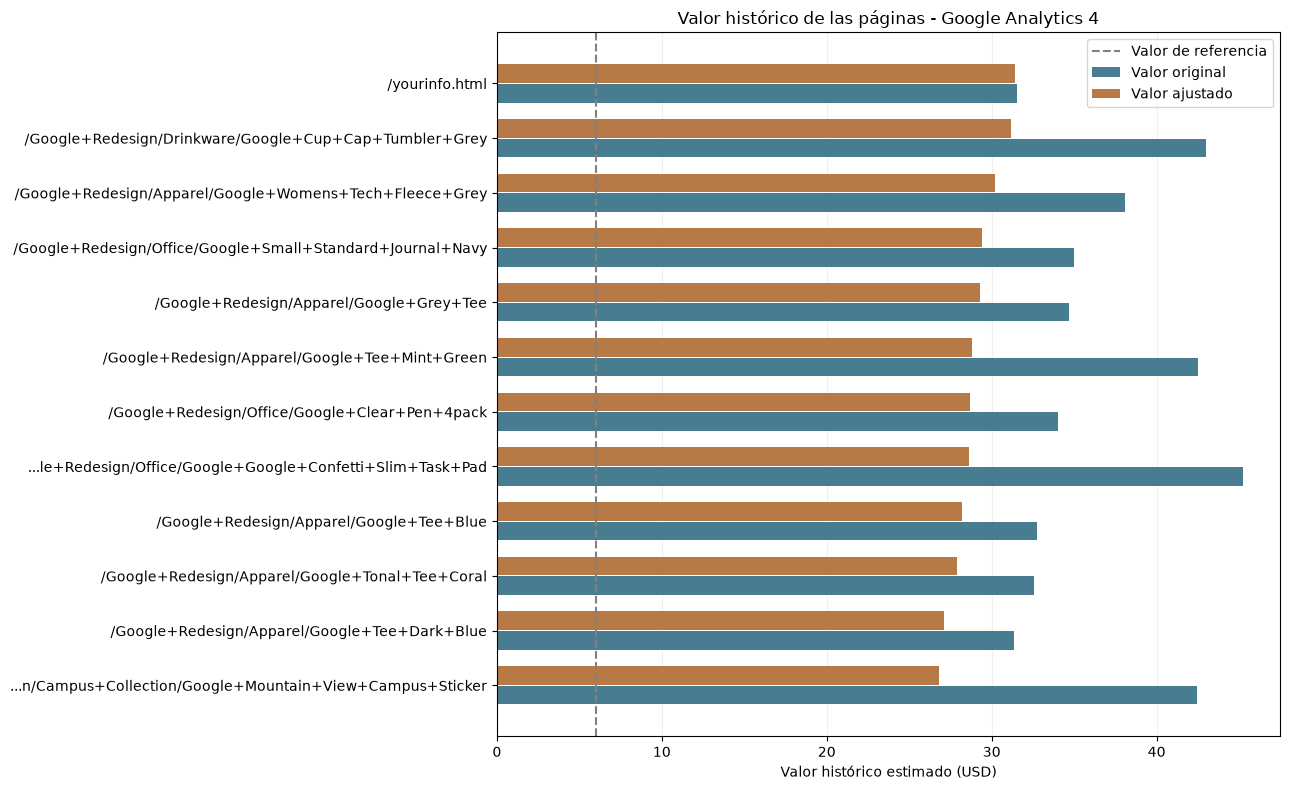

In [6]:
top_paginas = (
    valores_paginas[valores_paginas["sesiones_historicas"] >= 30]
    .nlargest(12, "Valor_ajustado")
    .sort_values("Valor_ajustado")
)

etiquetas = [
    urlsplit(url).path or "/"
    for url in top_paginas["pagina"]
]

etiquetas = [
    "..." + etiqueta[-55:] if len(etiqueta) > 58 else etiqueta
    for etiqueta in etiquetas
]

y = np.arange(len(top_paginas))

fig, ax = plt.subplots(figsize=(13, 8))

ax.barh(
    y - 0.18,
    top_paginas["Valor_historico"],
    height=0.34,
    color="#487D91",
    label="Valor original"
)

ax.barh(
    y + 0.18,
    top_paginas["Valor_ajustado"],
    height=0.34,
    color="#B77946",
    label="Valor ajustado"
)

ax.axvline(
    valor_referencia,
    linestyle="--",
    color="gray",
    label="Valor de referencia"
)

ax.set_yticks(y)
ax.set_yticklabels(etiquetas)
ax.set_xlabel("Valor histórico estimado (USD)")
ax.set_title("Valor histórico de las páginas - Google Analytics 4")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Interpretación**

El suavizado permite obtener estimaciones más prudentes sin necesidad de descartar las páginas con poco historial, aunque para esta visualización hemos seleccionado únicamente páginas con al menos 30 sesiones históricas.

## 4. Estimación del valor de una nueva sesión

### 4.1. Implementación de la función

Como propuesta de este proyecto, hemos desarrollado un indicador inspirado en la métrica Page Value de Universal Analytics, incorporando una técnica de suavizado estadístico. Estimamos el valor de una sesión mediante la media de los valores históricos ajustados de las páginas distintas visitadas.

Cada página se contabiliza una sola vez. Las páginas desconocidas reciben el valor general de referencia y se excluyen las rutas de pago y confirmación identificadas anteriormente.

$$
PageValue_{estimado}(s)=\frac{1}{|P_s|}\sum_{p\in P_s}V_{ajustado}(p)
$$

El cálculo utiliza únicamente información histórica y las páginas visitadas hasta el momento de la predicción.

Si la sesión no contiene páginas válidas tras aplicar la limpieza y los filtros, la función devuelve NaN, ya que no dispone de información suficiente para calcular el indicador.

In [7]:
import re

# Diccionario de valores históricos ajustados
diccionario_paginas = valores_paginas.set_index(
    "pagina"
)["Valor_ajustado"].to_dict()


def estimar_pagevalue(paginas_visitadas):
    """Estima el valor histórico de una sesión."""

    # Eliminar parámetros y fragmentos de las URLs
    paginas = [
        re.sub(r"[?#].*$", "", url.strip())
        for url in paginas_visitadas
        if url.strip()
    ]

    # Eliminar duplicados y páginas excluidas
    paginas = list(dict.fromkeys(paginas))

    paginas = [
        pagina for pagina in paginas
        if not re.search(
            patron,
            urlsplit(pagina).path.lower()
        )
    ]

    if not paginas:
        return np.nan

    # Consultar valores históricos
    valores = [
        diccionario_paginas.get(pagina, valor_referencia)
        for pagina in paginas
    ]

    return float(np.mean(valores))

### 4.2. Ejemplos de aplicación

Simulamos cuatro sesiones posteriores al periodo histórico para comprobar el funcionamiento del indicador con páginas conocidas, páginas nuevas y visitas repetidas.

In [8]:
pagina_1 = valores_paginas.iloc[0]["pagina"]
pagina_2 = valores_paginas.iloc[4]["pagina"]
pagina_3 = valores_paginas.iloc[5]["pagina"]

pagina_nueva = (
    "https://shop.googlemerchandisestore.com/producto-nuevo"
)

sesiones_ejemplo = {
    "Sesión con páginas conocidas": [
        pagina_1, pagina_2, pagina_3
    ],
    "Sesión con una página nueva": [
        pagina_1, pagina_2, pagina_3, pagina_nueva
    ],
    "Sesión con visitas repetidas": [
        pagina_1, pagina_2, pagina_3, pagina_1, pagina_2
    ],
    "Sesión sin historial": [
        pagina_nueva
    ]
}

resultados_ejemplo = pd.DataFrame([
    {
        "Sesion": nombre,
        "Paginas diferentes": len(set(paginas)),
        "PageValue estimado": estimar_pagevalue(paginas)
    }
    for nombre, paginas in sesiones_ejemplo.items()
])

display(resultados_ejemplo.round(4))

# Comprobaciones de funcionamiento
assert np.isclose(
    estimar_pagevalue(sesiones_ejemplo["Sesión con páginas conocidas"]),
    estimar_pagevalue(sesiones_ejemplo["Sesión con visitas repetidas"])
)

assert np.isclose(
    estimar_pagevalue([pagina_nueva]),
    valor_referencia
)

assert np.isnan(estimar_pagevalue([]))

print("Comprobaciones superadas correctamente.")

,Sesion,Paginas diferentes,PageValue estimado
0,Sesión con páginas conocidas,3,8.1110
1,Sesión con una página nueva,4,7.5807
2,Sesión con visitas repetidas,3,8.1110
3,Sesión sin historial,1,5.9898


Comprobaciones superadas correctamente.


**Interpretación**

- La sesión formada por las tres páginas conocidas obtiene un valor estimado de 8,11 USD.
- Al incorporar una página desconocida, el valor disminuye a 7,58 USD.
- Las visitas repetidas no alteran el resultado.
- Una página sin historial recibe el valor de referencia de 5,99 USD.

La función nos deja calcular el indicador sin conocer el resultado de la sesión actual.

## 5. Conclusiones y limitaciones

La demostración muestra cómo construir un indicador similar a `PageValues` utilizando datos de GA4.

En una tienda real los valores históricos podrían actualizarse diariamente y utilizarse durante la navegación del usuario. El suavizado permite incorporar páginas con pocas visitas o sin historial.

La propuesta evita utilizar el resultado futuro de la sesión que se desea analizar.

Sin embargo no reproduce exactamente la métrica original de Universal Analytics ni se ha evaluado su capacidad predictiva como sustituto de `PageValues` en nuestro modelo.